# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [2]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from roi_processing import *

## Read main path to .zarr file

In [ ]:
import os
import glob
import h5py
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon
from shapely.ops import unary_union

def load_featuredata(h5_path):
    """
    Reads a feature_data_*.hdf5 and returns a nested dict:
      {
        cell_id1: {
          'zIndex_0': {
            'p_0': ndarray(shape=(N,2)),
            'p_1': ndarray(shape=(M,2)),
            ...
          },
          ...
        },
        ...
      }
    """
    featuredata = {}
    with h5py.File(h5_path, "r") as f:
        root = f.get("featuredata")
        if root is None:
            raise KeyError("No /featuredata group found in the file.")
        
        for cell_id, cell_grp in root.items():
            zs = {}
            for z_name, z_grp in cell_grp.items():
                if not isinstance(z_grp, h5py.Group):
                    continue
                polys = {}
                for p_name, p_grp in z_grp.items():
                    if not isinstance(p_grp, h5py.Group):
                        continue
                    coords = p_grp.get("coordinates")
                    if coords is None:
                        continue
                    polys[p_name] = coords[:]  # numpy array
                if polys:
                    zs[z_name] = polys
            if zs:
                featuredata[cell_id] = zs
    return featuredata

# MAIN: Load all feature_data_*.hdf5 files
def load_all_feature_data(folder):
    h5_files = sorted(glob.glob(os.path.join(folder, "feature_data_*.hdf5")))
    all_records = []

    for h5_path in h5_files:
        sample_id = os.path.splitext(os.path.basename(h5_path))[0].split("_")[-1]  # e.g., '993'
        featuredata = load_featuredata(h5_path)

        for cid, zdict in featuredata.items():
            for z, pdict in zdict.items():
                for pname, coords in pdict.items():
                    all_records.append({
                        "sample_id": sample_id,
                        "cell_id": cid,
                        "z_index": z,
                        "polygon_id": pname,
                        "coordinates": coords  # numpy array
                    })

        print(f"Loaded {len(featuredata)} cells from {h5_path}.")

    print(f"\nTotal records: {len(all_records)}")
    return all_records

def coords_to_polygon(arr):
    """
    Turn an arbitrary ndarray‐like into a valid shapely.Polygon,
    or return None if it can’t be made valid.
    """
    coords = np.asarray(arr)
    # flatten trailing dims, e.g. shape (N,2,1) → (N,2)
    if coords.ndim > 2:
        coords = coords.reshape(-1, coords.shape[-1])
    # if someone passed a flat list [x0,y0,x1,y1,…]
    if coords.ndim == 1 and coords.size % 2 == 0:
        coords = coords.reshape(-1, 2)

    # must now be (N,2)
    if coords.ndim != 2 or coords.shape[1] != 2:
        return None
    # need at least 3 points
    if coords.shape[0] < 3:
        return None

    try:
        poly = Polygon(coords)
        # optionally ensure it’s valid:
        if not poly.is_valid:
            poly = poly.buffer(0)  # fix minor self‐intersections
        return poly
    except Exception:
        return None

# Example usage
folder = "/media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries"
all_feature_records = load_all_feature_data(folder)

# Inspect a few entries
for r in all_feature_records[:3]:
    print(f"Sample {r['sample_id']}, Cell {r['cell_id']}, {r['z_index']}, {r['polygon_id']}, coords shape: {r['coordinates'].shape}")

# ───── assume all_feature_records is already defined ─────
df = pd.DataFrame(all_feature_records)

# build polygons safely
df["geometry"] = df["coordinates"].apply(coords_to_polygon)

# drop any rows that failed
df = df.dropna(subset=["geometry"])

# group by cell_id → union all polys for each cell
cell_geoms = (
    df
    .groupby("cell_id")["geometry"]
    .apply(lambda geoms: unary_union(list(geoms)))
    .reset_index()
    .rename(columns={"cell_id":"cell_ID"})
)

# make a GeoDataFrame
gdf = gpd.GeoDataFrame(
    cell_geoms.set_index("cell_ID"),
    geometry="geometry",
    crs=None  # set your CRS if you have one
)

print(gdf.head())



Loaded 10 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_0.hdf5.
Loaded 46 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_100.hdf5.
Loaded 59 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_1000.hdf5.
Loaded 7 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_1001.hdf5.
Loaded 35 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_1002.hdf5.
Loaded 38 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_1003.hdf5.
Loaded 49 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptormap_r1s1/Replicate1/cell_boundaries/feature_data_1004.hdf5.
Loaded 57 cells from /media/sergio/Meninges/troutpy/raw/merscope_receptorm

In [ ]:
import os
import glob
import h5py
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import unary_union

import time
import numpy as np

# just once, at the top of your script:
ts = int(time.time())         # e.g. 1713950400 (10 digits, seconds since epoch)
task_idx = 1                  # your pipeline task number

def make_eid_arith(row):
    tile = int(row["sample_id"])       # must be <10000
    geom = int(row["ID"])              # must be <1000
    # pack them so there’s no overlap:
    #  ts:   *100 → leaves space for task_idx (2 digits)
    #  *10000 → leaves space for tile (4 digits)
    #  *1000 → leaves space for geom (3 digits)
    eid = (((ts * 100) + task_idx) * 10_000 + tile) * 1_000 + geom
    return np.int64(eid)

df["geometry"] = df["coordinates"].apply(coords_to_polygon)
df = df.dropna(subset=["geometry"])  # drop any failed polygons

# 2) Group per Z-slice, build a MultiPolygon for each (sample, cell, z_index)
rows = []
for (sample_id, cell_id, zstr), sub in df.groupby(["sample_id","cell_id","z_index"]):
    geoms = list(sub["geometry"])
    uni = unary_union(geoms)
    # ensure MultiPolygon (even if only one Polygon)
    if isinstance(uni, Polygon):
        mp = MultiPolygon([uni])
    elif isinstance(uni, MultiPolygon):
        mp = uni
    else:
        # fallback: try wrapping each part
        mp = MultiPolygon([g for g in geoms if isinstance(g, Polygon)])
    rows.append({
        "sample_id": sample_id,
        "cell_id":   cell_id,
        "z_index":   zstr,
        "geometry":  mp
    })

slice_df = pd.DataFrame(rows)

# 3) Build the Vizgen Parquet table
# — reset index for the parquet “ID”
slice_df = slice_df.reset_index(drop=True).reset_index().rename(columns={"index":"ID"})

# — numeric ZIndex & compute ZLevel (µm)
zspacing = 5.0  # <–– your Z-step in microns
slice_df["ZIndex"] = slice_df["z_index"].str.extract(r"(\d+)").astype(int)
slice_df["ZLevel"] = slice_df["ZIndex"] * zspacing

# — build EntityID: ts(14) + task(02) + tile/sample(04) + geom/ID(06)
analysis_ts = 20250425_120000  # e.g. YYYYMMDD_HHMMSS as integer
task_idx     = 1
def make_eid(row):
    ts  = f"{analysis_ts:014d}"
    tsk = f"{task_idx:02d}"
    tile= f"{int(row['sample_id']):04d}"
    geom= f"{int(row['ID']):06d}"
    return np.int64(ts + tsk + tile + geom)

#slice_df["EntityID"]   = slice_df.apply(make_eid, axis=1)
# Then, instead of your old apply, do:
slice_df["EntityID"] = slice_df.apply(make_eid_arith, axis=1)

slice_df["Name"]       = "cell_boundary"
slice_df["Type"]       = "cell"
slice_df["ParentID"]   = pd.NA
slice_df["ParentType"] = pd.NA

# 4) Select & reorder columns per Vizgen spec
out = slice_df[["ID", "EntityID", "Name", "Type","ZIndex", "ZLevel", "geometry", "ParentID", "ParentType"]]

# 5) Turn into a GeoDataFrame & write parquet
out_gdf = gpd.GeoDataFrame(out,crs=None)# geometry="geometry", crs=None)


In [79]:
path_data='/media/sergio/Meninges/troutpy/raw/msbrain_receptormap_r2s2'
# 5) Turn into a GeoDataFrame & write parquet
out_gdf = gpd.GeoDataFrame(out,crs=None)# geometry="geometry", crs=None)
out_gdf.to_parquet(os.path.join(path_data, 'cell_boundaries.parquet'), engine='pyarrow', index=False)

In [80]:
sdata=spatialdata_io.merscope(path_data)

INFO     The column "global_x" has now been renamed to "x"; the column "x" was already present in the dataframe,   
         and will be dropped.                                                                                      
INFO     The column "global_y" has now been renamed to "y"; the column "y" was already present in the dataframe,   
         and will be dropped.                                                                                      


ValueError: Column named geometry already exists

In [ ]:
print(get_transformation(sdata["raw_msbrain_receptormap_r2s2_transcripts"]))

In [78]:
sdata

SpatialData object
├── Images
│     └── 'raw_msbrain_receptormap_r2s2_z3': DataTree[cyx] (2, 90936, 89085), (2, 45468, 44542), (2, 22734, 22271), (2, 11367, 11135), (2, 5683, 5567)
├── Points
│     └── 'raw_msbrain_receptormap_r2s2_transcripts': DataFrame with shape: (<Delayed>, 7) (2D points)
├── Shapes
│     └── 'segmented': GeoDataFrame shape: (78329, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (84172, 483)
with coordinate systems:
    ▸ 'global', with elements:
        raw_msbrain_receptormap_r2s2_z3 (Images), raw_msbrain_receptormap_r2s2_transcripts (Points), segmented (Shapes)

In [ ]:
sdata.ge

SpatialData object
├── Images
│     └── 'raw_msbrain_receptormap_r2s2_z3': DataTree[cyx] (2, 90936, 89085), (2, 45468, 44542), (2, 22734, 22271), (2, 11367, 11135), (2, 5683, 5567)
├── Points
│     └── 'raw_msbrain_receptormap_r2s2_transcripts': DataFrame with shape: (<Delayed>, 7) (2D points)
└── Tables
      └── 'table': AnnData (84172, 483)
with coordinate systems:
    ▸ 'global', with elements:
        raw_msbrain_receptormap_r2s2_z3 (Images), raw_msbrain_receptormap_r2s2_transcripts (Points)

In [48]:
sdata['segmented']=sd.models.ShapesModel.parse(gdf)

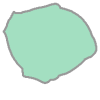

In [58]:
sdata['segmented']['geometry'][10]

INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' do disable this    
         behaviour.                                                                                                
INFO     alpha component of given RGBA value for outline color is discarded, because outline_alpha takes precedent.


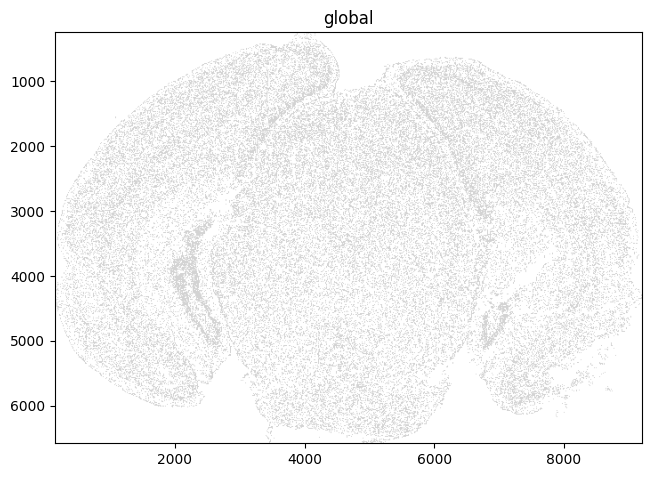

In [70]:
import spatialdata_plot as sdp  # noqa: F401
sdata.pl.render_shapes().pl.show()

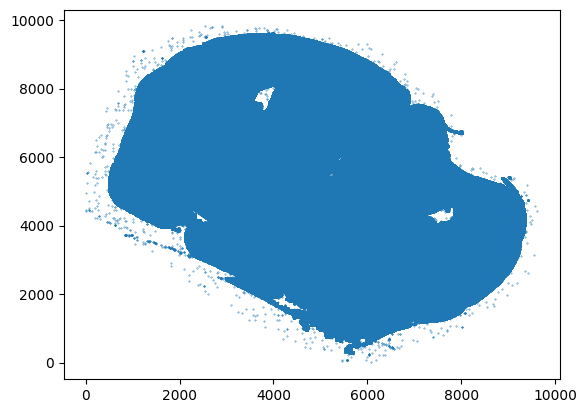

In [ ]:
tran=sdata['raw_msbrain_receptormap_r2s2_transcripts'].compute()
plt.scatter(tran['x'],tran['y'],s=0.02)

In [64]:
sdata_shapes = sdata.aggregate(values="raw_msbrain_receptormap_r2s2_transcripts", by="segmented", value_key="gene", agg_func="count")
sdata_shapes

SpatialData object
├── Shapes
│     └── 'segmented': GeoDataFrame shape: (78329, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (78329, 649)
with coordinate systems:
    ▸ 'global', with elements:
        segmented (Shapes)

<78329x649 sparse matrix of type '<class 'numpy.int64'>'
	with 0 stored elements in Compressed Sparse Row format>

In [65]:
sc.pl.spatial(sdata_shapes['table'],spot_size=20)

KeyError: "Could not find 'spatial' or 'X_spatial' in .obsm"

In [42]:
# after you’ve built your flat GeoDataFrame `gdf`
# assume you kept a "z_index" column
sdata.shapes["cell_boundaries"] = gdf


ValueError: :class:`geopandas.GeoDataFrame` does not contain `transform`. Please use ShapesModel.parse() to construct data that is guaranteed to be valid.

In [41]:
sdata['raw_msbrain_receptormap_r2s2_transcripts'].compute()

,x,y,barcode_id,fov,Unnamed: 0,gene,global_z
0,94.497154,5830.9800,22,0,0,Adgre1,0.0
1,27.500680,5546.4565,22,2,1,Adgre1,0.0
2,29.215889,5546.4487,22,2,2,Adgre1,0.0
3,45.469160,5569.9966,22,2,3,Adgre1,3.0
4,29.123753,5546.3000,131,2,4,Gpr22,0.0
...,...,...,...,...,...,...,...
981016,9483.610000,4038.2480,131,1637,61189762,Gpr22,0.0
981017,9463.007000,4119.2437,447,1637,61189763,Ephb6,0.0
981018,9475.143000,4296.1230,181,1638,61189764,Mrgpra3,0.0
981019,9615.522000,4416.0967,131,1639,61189765,Gpr22,0.0


In [6]:
sdata['raw_msbrain_receptormap_r2s2_transcripts'].compute()

,x,y,Unnamed: 0,barcode_id,fov,gene,global_z
0,94.497154,5830.9800,0,22,0,Adgre1,0.0
1,27.500680,5546.4565,1,22,2,Adgre1,0.0
2,29.215889,5546.4487,2,22,2,Adgre1,0.0
3,45.469160,5569.9966,3,22,2,Adgre1,3.0
4,29.123753,5546.3000,4,131,2,Gpr22,0.0
...,...,...,...,...,...,...,...
981016,9483.610000,4038.2480,61189762,131,1637,Gpr22,0.0
981017,9463.007000,4119.2437,61189763,447,1637,Ephb6,0.0
981018,9475.143000,4296.1230,61189764,181,1638,Mrgpra3,0.0
981019,9615.522000,4416.0967,61189765,131,1639,Gpr22,0.0


In [3]:
troutpy.pp.cosmx_converter(sdata)

Global Image Canvas Dimensions: Width = 37811, Height = 46004
Image stitching complete!
Global Label Canvas Dimensions: Width = 32134, Height = 46004
Label stitching complete!


In [5]:
sdata['transcripts']

,gene,cell_ID,z_raw,y,x,fov,CellComp,local_x,local_y,transcript_id,overlaps_cell,overlaps_nuclei,control_probe
npartitions=1,,,,,,,,,,,,,
0,category[known],int64,int64,float64,float64,int64,string,float64,float64,int64,bool,bool,bool
9531240,...,...,...,...,...,...,...,...,...,...,...,...,...


## Deprecated code for converting cosmx data to standard troutpy data

In [ ]:
import numpy as np
import xarray as xr
from spatial_image import to_spatial_image

# Assuming each tile is the same size (e.g., from tile "1_image")
tile_ids=list(sdata.images.data.keys())
tile_ids_image=tile_ids
sample_tile = sdata[tile_ids[0]]
tile_height = sample_tile.data.shape[1]  # e.g., 3648
tile_width  = sample_tile.data.shape[2]  # e.g., 5472

# Extract global offsets from the transformation matrix for each tile
x_offsets = {}
y_offsets = {}
for tid in tile_ids:
    # Access the transformation matrix
    transform_matrix = sdata[tid].transform['global'].matrix
    x_offsets[tid] = transform_matrix[0, 2]
    y_offsets[tid] = transform_matrix[1, 2]

# Compute the global canvas extents using the offsets
global_x_min = min(x_offsets.values())
global_y_min = min(y_offsets.values())
global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

canvas_width  = int(np.ceil(global_x_max - global_x_min))
canvas_height = int(np.ceil(global_y_max - global_y_min))

print("Global Canvas Dimensions: Width =", canvas_width, ", Height =", canvas_height)

# Initialize a canvas for the stitched image (assuming 3-channel RGB)
global_image_canvas = np.zeros((3, canvas_height, canvas_width), dtype=np.uint8)

# Stitch each tile into the global canvas
for tid in tile_ids:
    # Compute the offset relative to the global minimum positions
    x_offset = int(np.round(x_offsets[tid] - global_x_min))
    y_offset = int(np.round(y_offsets[tid] - global_y_min))
    
    # Retrieve the tile image data (expected shape: (3, tile_height, tile_width))
    tile_image = sdata[tid].data

    # Place the tile into the global canvas
    global_image_canvas[:, y_offset:y_offset+tile_height, x_offset:x_offset+tile_width] = tile_image

# Convert the stitched image array to an xarray DataArray and then to a spatial image object
stitched_da = xr.DataArray(global_image_canvas, dims=("c", "y", "x"))

print("Stitching complete!")


Global Canvas Dimensions: Width = 37811 , Height = 46004
Stitching complete!


In [ ]:
import numpy as np
import xarray as xr
#from spatialdata import Label

# Assuming each label tile is the same size (e.g., from tile "1_labels")
tile_ids=list(sdata.labels.data.keys())
#sample_tile = sdata[tile_ids[0]]
sample_label = sdata[tile_ids[0]]
tile_height = sample_label.data.shape[0]  # (y dimension), e.g., 3648
tile_width  = sample_label.data.shape[1]  # (x dimension), e.g., 5472

# Extract global offsets for each tile from the corresponding image's transformation matrix.
# (Labels are aligned with images, so we use sdata[f"{tid}_image"].transform)
x_offsets = {}
y_offsets = {}
for tid in tile_ids:
    # Get the transformation matrix from the associated image tile
    transform_matrix = sdata[f"{tid}"].transform['global'].matrix
    x_offsets[tid] = transform_matrix[0, 2]
    y_offsets[tid] = transform_matrix[1, 2]

# Compute the overall extents of the global canvas for labels
global_x_min = min(x_offsets.values())
global_y_min = min(y_offsets.values())
global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

canvas_width  = int(np.ceil(global_x_max - global_x_min))
canvas_height = int(np.ceil(global_y_max - global_y_min))

print("Global Canvas Dimensions (Labels): Width =", canvas_width, ", Height =", canvas_height)

# Initialize a canvas for the stitched label image
global_label_canvas = np.zeros((canvas_height, canvas_width), dtype=sample_label.data.dtype)

# Place each label tile into the global canvas using its computed offsets
for tid in tile_ids:
    x_offset = int(np.round(x_offsets[tid] - global_x_min))
    y_offset = int(np.round(y_offsets[tid] - global_y_min))
    
    tile_label = sdata[f"{tid}"].data  # shape: (tile_height, tile_width)
    
    # Place the tile's labels into the global canvas
    global_label_canvas[y_offset:y_offset+tile_height, x_offset:x_offset+tile_width] = tile_label

# Wrap the stitched labels into an xarray DataArray
stitched_labels_da = xr.DataArray(global_label_canvas, dims=("y", "x"))

# Optionally, convert the DataArray to a proper Label object (if using spatialdata Label methods)
#stitched_label_object = Label.from_xarray(stitched_labels_da)

print("Label stitching complete!")


Global Canvas Dimensions (Labels): Width = 32134 , Height = 46004
Label stitching complete!


In [155]:
import pandas as pd

alldf = []
for id in tile_ids:
    transcripts = sdata[id].compute()
    alldf.append(transcripts)

# Concatenate all tile dataframes
alltranscripts = pd.concat(alldf, ignore_index=True)

# Store original local coordinates
alltranscripts['local_x'] = alltranscripts['x']
alltranscripts['local_y'] = alltranscripts['y']

del alltranscripts['y']
del alltranscripts['x']

# Rename global coordinates and target
alltranscripts.rename(columns={
    'x_global_px': 'x',
    'y_global_px': 'y',
    'target': 'gene'
}, inplace=True)

# Generate unique transcript_id
alltranscripts['transcript_id'] = [i for i in range(len(alltranscripts))]

# overlaps_cell is True if cell_ID is not 0
alltranscripts['overlaps_cell'] = alltranscripts['cell_ID'] != 0

# overlaps_nuclei is True if CellComp is 'Nuclear'
alltranscripts['overlaps_nuclei'] = alltranscripts['CellComp'] == 'Nuclear'
alltranscripts['overlaps_nuclei'].fillna(False,inplace=True)
alltranscripts['overlaps_nuclei']=alltranscripts['overlaps_nuclei'].astype(bool)

# control_probe is True if gene starts with 'NegPrb'
alltranscripts['control_probe'] = alltranscripts['gene'].str.startswith('NegPrb')


In [ ]:
### format sdata table
sdata['table'].obsm['spatial']=sdata['table'].obsm['global']

In [177]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import spatialdata as sd
import spatialdata_plot as sdp  # noqa: F401
import squidpy as sq
from shapely.geometry import Point
from spatialdata.models import Image2DModel, Labels2DModel

img_for_sdata = Image2DModel.parse(data=stitched_da, scale_factors=(2,2),c_coords=sdata[tile_ids_image[0]].c.data)
parsed_transcripts=sd.models.PointsModel.parse(alltranscripts)
labels_for_sdata = Labels2DModel.parse(data=stitched_labels_da, scale_factors=(2,2))

sdata2 = sd.SpatialData(
    images={"morphology_focus": img_for_sdata},
    labels={"labels": labels_for_sdata},
    tables={"adata": sdata['table']},
    points={"transcripts": parsed_transcripts},
)


NameError: name 'tile_ids_image' is not defined

In [ ]:
import numpy as np
import xarray as xr
from spatial_image import to_spatial_image
import pandas as pd
import spatialdata as sd
from spatialdata.models import Image2DModel, Labels2DModel
from typing import Optional


def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches image tiles from SpatialData object into a single global image.

    Args:
        sdata: The input SpatialData object containing image tiles.

    Returns:
        An xarray DataArray representing the stitched global image.
    """
    tile_ids = list(sdata.images.data.keys())
    sample_tile = sdata[tile_ids[0]]
    tile_height = sample_tile.data.shape[1]
    tile_width = sample_tile.data.shape[2]

    x_offsets = {}
    y_offsets = {}
    for tid in tile_ids:
        transform_matrix = sdata[tid].transform['global'].matrix
        x_offsets[tid] = transform_matrix[0, 2]
        y_offsets[tid] = transform_matrix[1, 2]

    global_x_min = min(x_offsets.values())
    global_y_min = min(y_offsets.values())
    global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
    global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

    canvas_width = int(np.ceil(global_x_max - global_x_min))
    canvas_height = int(np.ceil(global_y_max - global_y_min))

    print(f"Global Image Canvas Dimensions: Width = {canvas_width}, Height = {canvas_height}")

    global_image_canvas = np.zeros((3, canvas_height, canvas_width), dtype=np.uint8)

    for tid in tile_ids:
        x_offset = int(np.round(x_offsets[tid] - global_x_min))
        y_offset = int(np.round(y_offsets[tid] - global_y_min))
        tile_image = sdata[tid].data
        global_image_canvas[:, y_offset:y_offset + tile_height, x_offset:x_offset + tile_width] = tile_image

    stitched_da = xr.DataArray(global_image_canvas, dims=("c", "y", "x"))
    print("Image stitching complete!")
    return stitched_da

def process_label_data(sdata: sd.SpatialData) -> xr.DataArray:
    """
    Stitches label tiles from SpatialData object into a single global label image.

    Args:
        sdata: The input SpatialData object containing label tiles.

    Returns:
        An xarray DataArray representing the stitched global label image.
    """
    tile_ids = list(sdata.labels.data.keys())
    sample_label = sdata[tile_ids[0]]
    tile_height = sample_label.data.shape[0]
    tile_width = sample_label.data.shape[1]

    x_offsets = {}
    y_offsets = {}
    for tid in tile_ids:
        transform_matrix = sdata[f"{tid}"].transform['global'].matrix
        x_offsets[tid] = transform_matrix[0, 2]
        y_offsets[tid] = transform_matrix[1, 2]

    global_x_min = min(x_offsets.values())
    global_y_min = min(y_offsets.values())
    global_x_max = max(x_offsets[tid] + tile_width for tid in tile_ids)
    global_y_max = max(y_offsets[tid] + tile_height for tid in tile_ids)

    canvas_width = int(np.ceil(global_x_max - global_x_min))
    canvas_height = int(np.ceil(global_y_max - global_y_min))

    print(f"Global Label Canvas Dimensions: Width = {canvas_width}, Height = {canvas_height}")

    global_label_canvas = np.zeros((canvas_height, canvas_width), dtype=sample_label.data.dtype)

    for tid in tile_ids:
        x_offset = int(np.round(x_offsets[tid] - global_x_min))
        y_offset = int(np.round(y_offsets[tid] - global_y_min))
        tile_label = sdata[f"{tid}"].data
        global_label_canvas[y_offset:y_offset + tile_height, x_offset:x_offset + tile_width] = tile_label

    stitched_labels_da = xr.DataArray(global_label_canvas, dims=("y", "x"))
    print("Label stitching complete!")
    return stitched_labels_da

def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    """
    Processes transcript data from SpatialData object, concatenating tiles and
    performing necessary transformations.

    Args:
        sdata: The input SpatialData object containing transcript data.

    Returns:
        A pandas DataFrame containing the processed transcript data.
    """
    tile_ids = list(sdata.points.data.keys()) #changed from sdata.labels to sdata.images
    alldf = []
    for id in tile_ids:
        transcripts = sdata[id].compute()
        alldf.append(transcripts)

    alltranscripts = pd.concat(alldf, ignore_index=True)

    alltranscripts['local_x'] = alltranscripts['x']
    alltranscripts['local_y'] = alltranscripts['y']

    del alltranscripts['y']
    del alltranscripts['x']

    alltranscripts.rename(columns={
        'x_global_px': 'x',
        'y_global_px': 'y',
        'target': 'gene'
    }, inplace=True)

    alltranscripts['transcript_id'] = [i for i in range(len(alltranscripts))]
    alltranscripts['overlaps_cell'] = alltranscripts['cell_ID'] != 0
    alltranscripts['overlaps_nuclei'] = alltranscripts['CellComp'] == 'Nuclear'
    alltranscripts['overlaps_nuclei'].fillna(False, inplace=True)
    alltranscripts['overlaps_nuclei'] = alltranscripts['overlaps_nuclei'].astype(bool)
    alltranscripts['control_probe'] = alltranscripts['gene'].str.startswith('NegPrb')

    sdata['table'].obsm['spatial'] = sdata['table'].obsm['global']
    return alltranscripts

def cosmx_converter(sdata: sd.SpatialData, copy: bool = False) -> sd.SpatialData:
    """
    Converts CosMX data from a SpatialData object into a new SpatialData object
    with processed image, label, and transcript data.

    Args:
        sdata: The input SpatialData object containing the raw CosMX data.
        copy: If True, returns a copy of the SpatialData object with the
            converted data. If False, modifies the original SpatialData object
            in place and returns it.

    Returns:
        A SpatialData object containing the converted data.  This is a *new*
        SpatialData object if copy is True, otherwise it's the *same* object
        as the input (modified in place).
    """


    sdata_out = sdata

    stitched_da = process_image_data(sdata_out)
    stitched_labels_da = process_label_data(sdata_out)
    parsed_transcripts = sd.models.PointsModel.parse(process_transcript_data(sdata_out))

    sdata_out.images = {"morphology_focus": Image2DModel.parse(data=stitched_da, scale_factors=(2,2),c_coords=sdata_out[list(sdata_out.images.keys())[0]].c.data)} # changed sdata to sdata_out
    sdata_out.labels = {"labels": Labels2DModel.parse(data=stitched_labels_da, scale_factors=(2,2))} # changed sdata to sdata_out
    sdata_out.points = {"transcripts": parsed_transcripts}



    return sdata if copy else None

AttributeError: 'AxesImage' object has no attribute 'set_title'

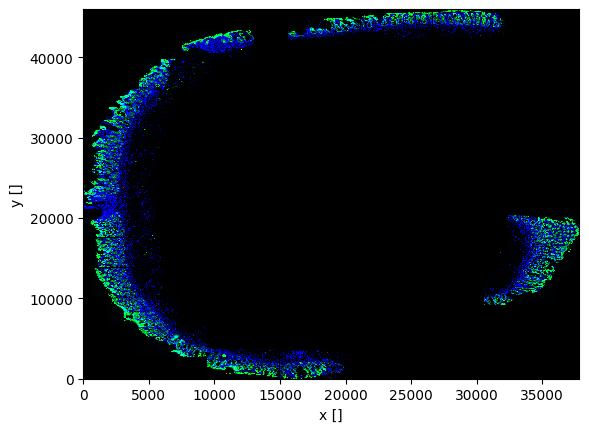

In [50]:
import matplotlib.pyplot as plt

# Visualize the DataArray using xarray's built-in imshow function
ax = stitched_image.plot.imshow(cmap="viridis", add_colorbar=True)
#ax.set_title("My DataArray Plot")
plt.show()


In [ ]:
sdata['1_image'].transform['global']

Affine (x, y -> x, y)
    [ 1.00000000e+00 -1.37253336e-16  1.71555556e+04]
    [-1.40753753e-16  1.00000000e+00  1.69755556e+05]
    [0. 0. 1.]

In [ ]:
sdata['1_image'].transform['global']

In [9]:
from spatial_image import to_spatial_image
from spatialdata import SpatialData
import xarray as xr
import numpy as np

# Example for stitching
stitched_image = np.zeros((3, H_total, W_total))  # e.g. (3, 3648 * 5, 5472 * 4)
# Place each tile in its correct (row, col) position
stitched_image[:, r*3648:(r+1)*3648, c*5472:(c+1)*5472] = image_tile

# Wrap in DataArray
stitched_da = xr.DataArray(stitched_image, dims=("c", "y", "x"))
image = to_spatial_image(stitched_da, scale=[1.0, 1.0])


NameError: name 'H_total' is not defined

In [6]:
sdata.points['1_points'].compute()

,x,y,target,cell_ID,CellComp,y_global_px,z_raw,x_global_px,fov
0,3202.20,2317.78,REG1A,0,<NA>,172073.335556,-1,20357.755556,1
1,1497.44,1262.72,NegPrb18,0,<NA>,171018.275556,-1,18652.995556,1
2,3184.02,1118.93,CD24,0,<NA>,170874.485556,-1,20339.575556,1
3,2745.73,1432.95,GZMB,0,<NA>,171188.505556,-1,19901.285556,1
4,2352.00,1466.90,REG1A,0,<NA>,171222.455556,-1,19507.555556,1
...,...,...,...,...,...,...,...,...,...
597652,2206.64,29.97,NR1H2,2656,Cytoplasm,169785.525556,7,19362.195556,1
597653,2251.75,19.65,GZMA,2656,Cytoplasm,169775.205556,8,19407.305556,1
597654,2231.49,40.24,MPO,2656,Cytoplasm,169795.795556,8,19387.045556,1
597655,2202.58,18.33,ACVR2A,2656,Cytoplasm,169773.885556,8,19358.135556,1


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' do disable this    
         behaviour.                                                                                                


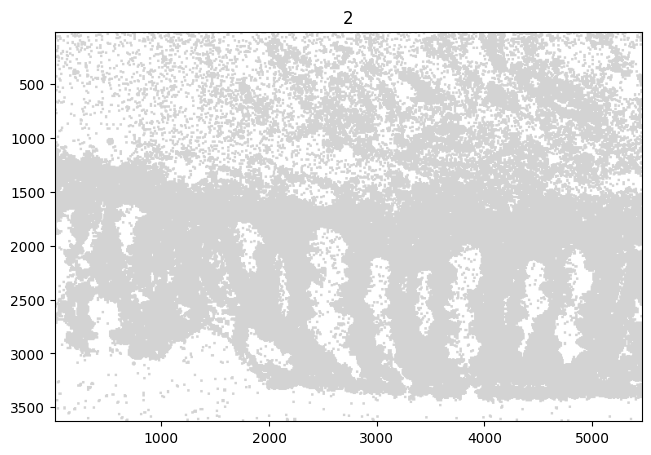

In [10]:
sdata.pl.render_points().pl.show(coordinate_systems=["2"])

INFO     Rasterizing image for faster rendering.                                                                   


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.2944162].


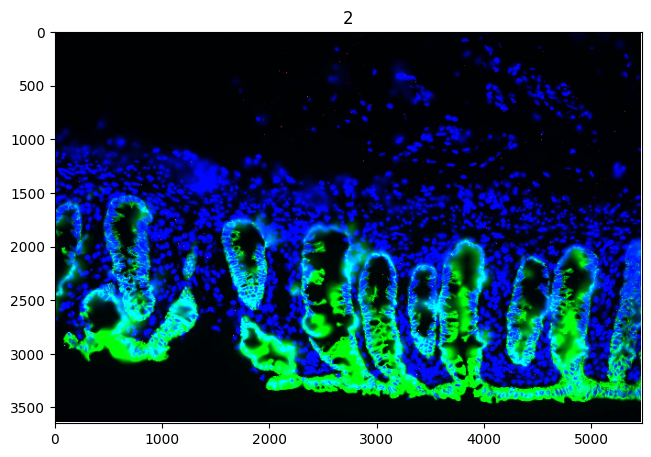

In [8]:
import spatialdata_plot
sdata.pl.render_images().pl.show(coordinate_systems=["2"])

In [14]:
sdata['table'].var

""
AATK
ABL1
ABL2
ACE
ACE2
...
NegPrb19
NegPrb20
NegPrb21
NegPrb22


In [34]:
inpath = "/media/sergio/Meninges/troutpy/xenium_msbrain_300/msbrain.zarr"
sdata=sd.read_zarr(inpath)

output_path = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300"

We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

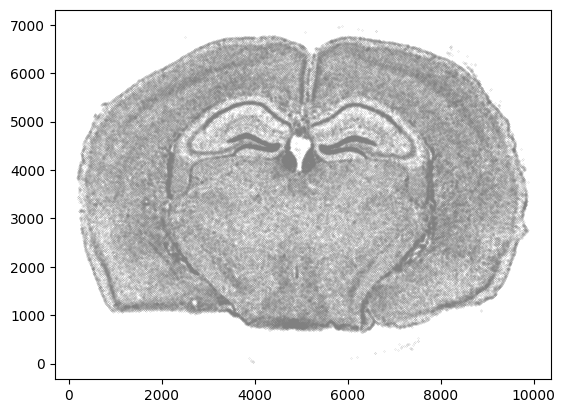

In [35]:
# Visualize using global coordinates
local_coords = sdata['table'].obsm['spatial']
# In case it's needed, chec transformations
#print(  get_transformation(sdata["nucleus_boundaries"]))
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.01,c='grey')

In [36]:
# ROI selection
bb_xmin =12000 # mix x 
bb_ymin= 18000 #min y
bb_xmax=23000 # max x
bb_ymax=35000 # max y

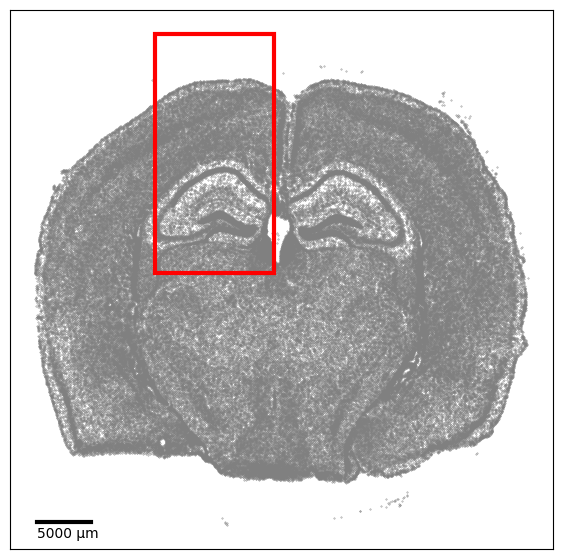

In [37]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata['table'].obsm['spatial'],
    bb_xmin=bb_xmin,
    bb_xmax=bb_xmax,
    bb_ymin=bb_ymin,
    bb_ymax=bb_ymax
)


Next, we select the ROI of interest

In [38]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],target_coordinate_system="global")


In [39]:
# Save metadata
metadata = generate_and_save_metadata(sdata=cropped_sdata,
    sample_id="mouse_brain_sample1",
    species="Mus musculus",technology="Visium",
    segmentation_method="nuclei_expanded",roi_name="cortex_ROI",
    tissue="brain",disease="control")


In [ ]:
# Define output paths

zarr_path = os.path.join(output_path,"data.zarr")
metadata_path = os.path.join(output_path,"metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)


ValueError: Attempt to save array to zarr with irregular chunking, please call `arr.rechunk(...)` first.

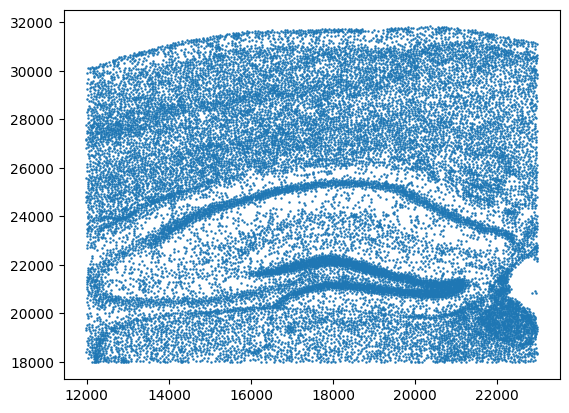

In [ ]:
spat=[g[0]*4.7 for g in cropped_sdata['table'].obsm['spatial']]
spat2=[g[1]*4.7 for g in cropped_sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.6,c='grey')

In [39]:
sdata['table'].var

,feature_types,genome,gene_names
gene_ids,,,
ENSMUSG00000026090,Gene Expression,Unknown,2010300C02Rik
ENSMUSG00000032281,Gene Expression,Unknown,Acsbg1
ENSMUSG00000035783,Gene Expression,Unknown,Acta2
ENSMUSG00000000530,Gene Expression,Unknown,Acvrl1
ENSMUSG00000036545,Gene Expression,Unknown,Adamts2
...,...,...,...
ENSMUSG00000045648,Gene Expression,Unknown,Vwc2l
ENSMUSG00000039474,Gene Expression,Unknown,Wfs1
ENSMUSG00000050919,Gene Expression,Unknown,Zfp366


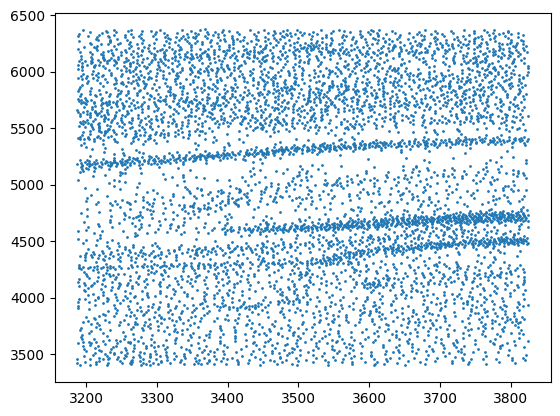

In [22]:
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=1)

In [23]:
transcripts=sdata['transcripts'].compute()
transcripts.reset_index(drop=True,inplace=True)
sdata['transcripts']=sd.models.PointsModel.parse(transcripts)